In [1]:
import pandas as pd
import numpy as np

# Set random seed agar hasil konsisten
np.random.seed(42)
n_samples = 1000

# 1. Jurusan (Kategorik Nominal)
jurusan_list = ['Sistem Informasi', 'Manajemen', 'Akuntansi', 'Ilmu Komunikasi']
prob_jurusan = [0.35, 0.30, 0.20, 0.15]
jurusan = np.random.choice(jurusan_list, n_samples, p=prob_jurusan)

# 2. Semester (Kategorik Ordinal)
semester = np.random.randint(1, 9, n_samples)

# 3. IPK (Numerik Kontinu)
base_ipk = np.random.normal(3.2, 0.4, n_samples)
jurusan_effect = {'Sistem Informasi': 0.1, 'Manajemen': -0.05, 'Akuntansi': 0.05, 'Ilmu Komunikasi': 0.0}
ipk = base_ipk + [jurusan_effect[j] for j in jurusan]
ipk = np.clip(ipk, 2.0, 4.0)
ipk = np.round(ipk, 2)

# 4. Usia (Numerik Kontinu)
usia = np.random.normal(20, 1.5, n_samples).astype(int)
usia = np.clip(usia, 17, 25)

# Membuat DataFrame
df = pd.DataFrame({
    'Jurusan': jurusan,
    'Semester': semester,
    'IPK': ipk,
    'Usia': usia
})

# Menyimpan ke CSV
df.to_csv('profil_mahasiswa.csv', index=False)
print("Dataset 1000 baris berhasil dibuat dan disimpan sebagai 'profil_mahasiswa.csv'")
df.head()

Dataset 1000 baris berhasil dibuat dan disimpan sebagai 'profil_mahasiswa.csv'


,Jurusan,Semester,IPK,Usia
0,Manajemen,7,2.15,18
1,Ilmu Komunikasi,4,4.00,20
2,Akuntansi,6,2.69,20
3,Manajemen,8,2.49,21
4,Sistem Informasi,8,3.71,22


In [2]:
print("=== Informasi Dataset ===")
print(df.info())

print("\n=== Statistik Deskriptif ===")
print(df.describe())

print("\n=== Distribusi Mahasiswa per Jurusan ===")
print(df['Jurusan'].value_counts())

print("\n=== Rata-rata IPK per Jurusan ===")
print(df.groupby('Jurusan')['IPK'].mean().sort_values(ascending=False))

print("\n=== Rata-rata Usia berdasarkan Semester ===")
print(df.groupby('Semester')['Usia'].mean())

print("\n=== Korelasi Antar Variabel Numerik ===")
print(df[['Semester', 'IPK', 'Usia']].corr())

=== Informasi Dataset ===
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Jurusan   1000 non-null   str    
 1   Semester  1000 non-null   int32  
 2   IPK       1000 non-null   float64
 3   Usia      1000 non-null   int64  
dtypes: float64(1), int32(1), int64(1), str(1)
memory usage: 39.7 KB
None

=== Statistik Deskriptif ===
          Semester          IPK         Usia
count  1000.000000  1000.000000  1000.000000
mean      4.453000     3.236870    19.525000
std       2.293698     0.389651     1.448265
min       1.000000     2.000000    17.000000
25%       2.000000     2.990000    19.000000
50%       4.000000     3.240000    19.000000
75%       6.000000     3.502500    20.000000
max       8.000000     4.000000    25.000000

=== Distribusi Mahasiswa per Jurusan ===
Jurusan
Sistem Informasi    365
Manajemen           306
Akuntansi           176
Ilmu Komunikasi

Matplotlib is building the font cache; this may take a moment.
C:\Users\adiet\AppData\Local\Temp\ipykernel_6492\1594866824.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Jurusan', ax=axes[0, 0], palette='viridis')
C:\Users\adiet\AppData\Local\Temp\ipykernel_6492\1594866824.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Semester', ax=axes[0, 1], palette='magma', order=sorted(df['Semester'].unique()))
C:\Users\adiet\AppData\Local\Temp\ipykernel_6492\1594866824.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns

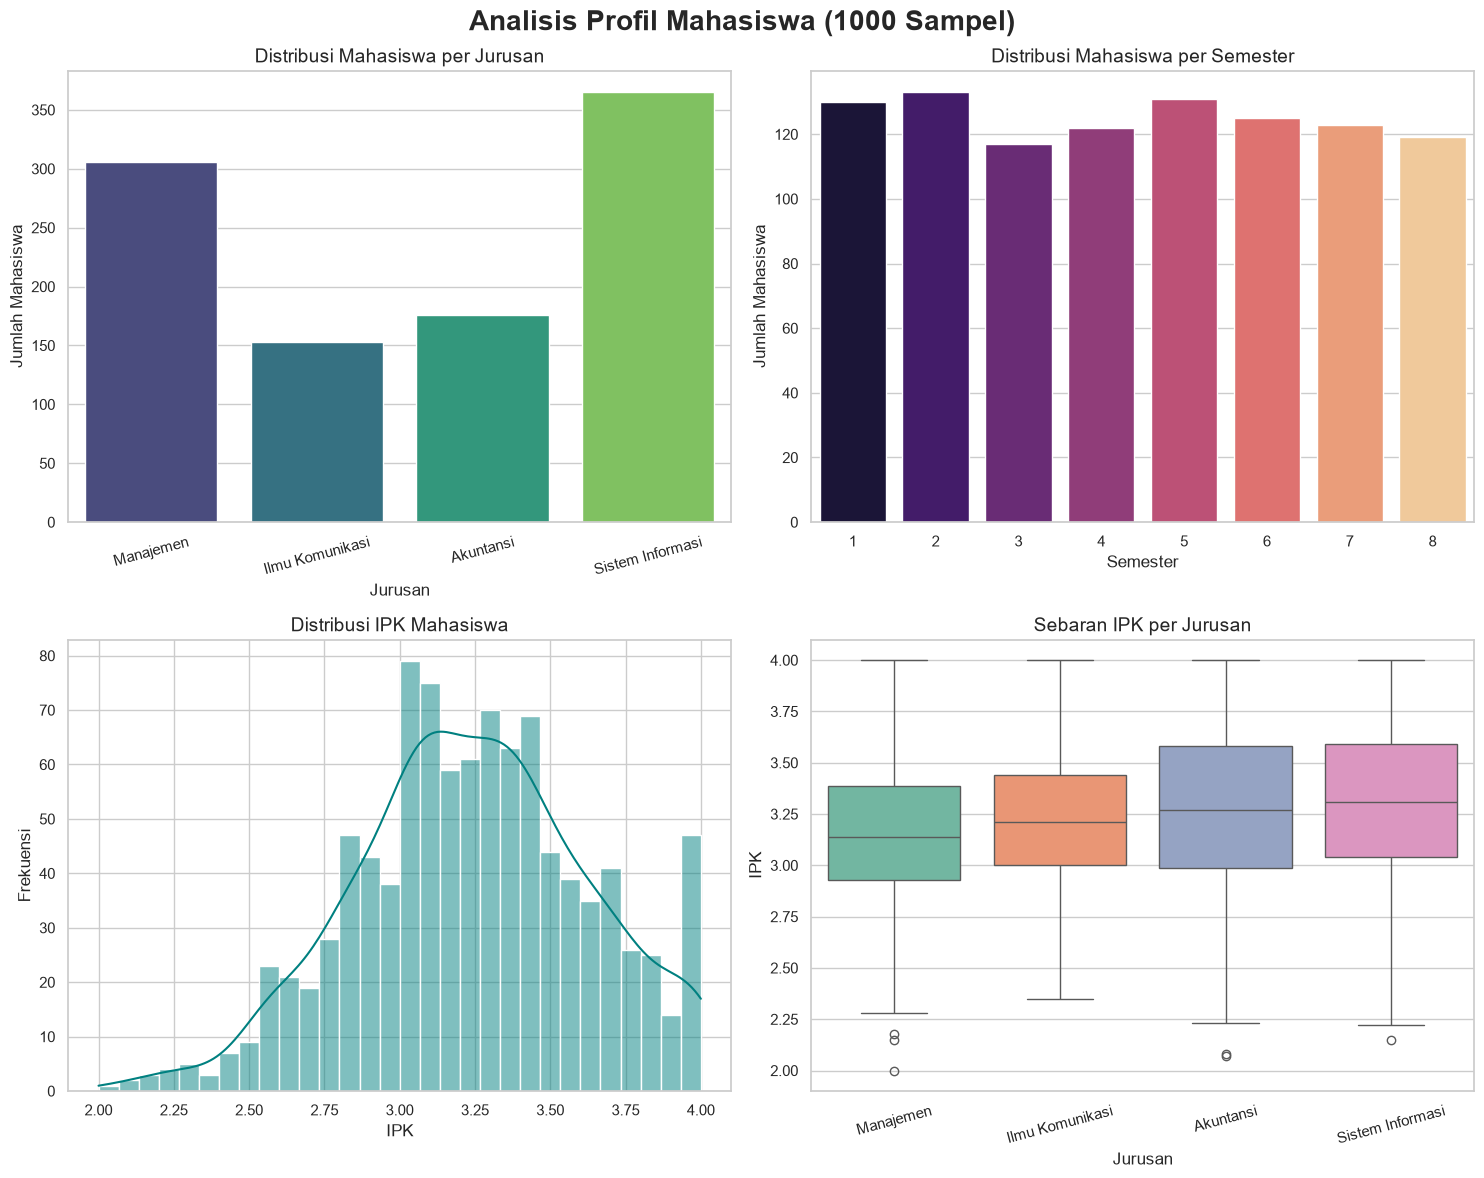

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Analisis Profil Mahasiswa (1000 Sampel)', fontsize=20, fontweight='bold')

# 1. Bar Chart: Jumlah Mahasiswa per Jurusan
sns.countplot(data=df, x='Jurusan', ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Distribusi Mahasiswa per Jurusan', fontsize=14)
axes[0, 0].set_ylabel('Jumlah Mahasiswa')
axes[0, 0].tick_params(axis='x', rotation=15)

# 2. Bar Chart Berurutan: Jumlah Mahasiswa per Semester
sns.countplot(data=df, x='Semester', ax=axes[0, 1], palette='magma', order=sorted(df['Semester'].unique()))
axes[0, 1].set_title('Distribusi Mahasiswa per Semester', fontsize=14)
axes[0, 1].set_ylabel('Jumlah Mahasiswa')

# 3. Histogram: Distribusi IPK
sns.histplot(data=df, x='IPK', kde=True, ax=axes[1, 0], color='teal', bins=30)
axes[1, 0].set_title('Distribusi IPK Mahasiswa', fontsize=14)
axes[1, 0].set_ylabel('Frekuensi')

# 4. Box Plot: Sebaran IPK berdasarkan Jurusan
sns.boxplot(data=df, x='Jurusan', y='IPK', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Sebaran IPK per Jurusan', fontsize=14)
axes[1, 1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

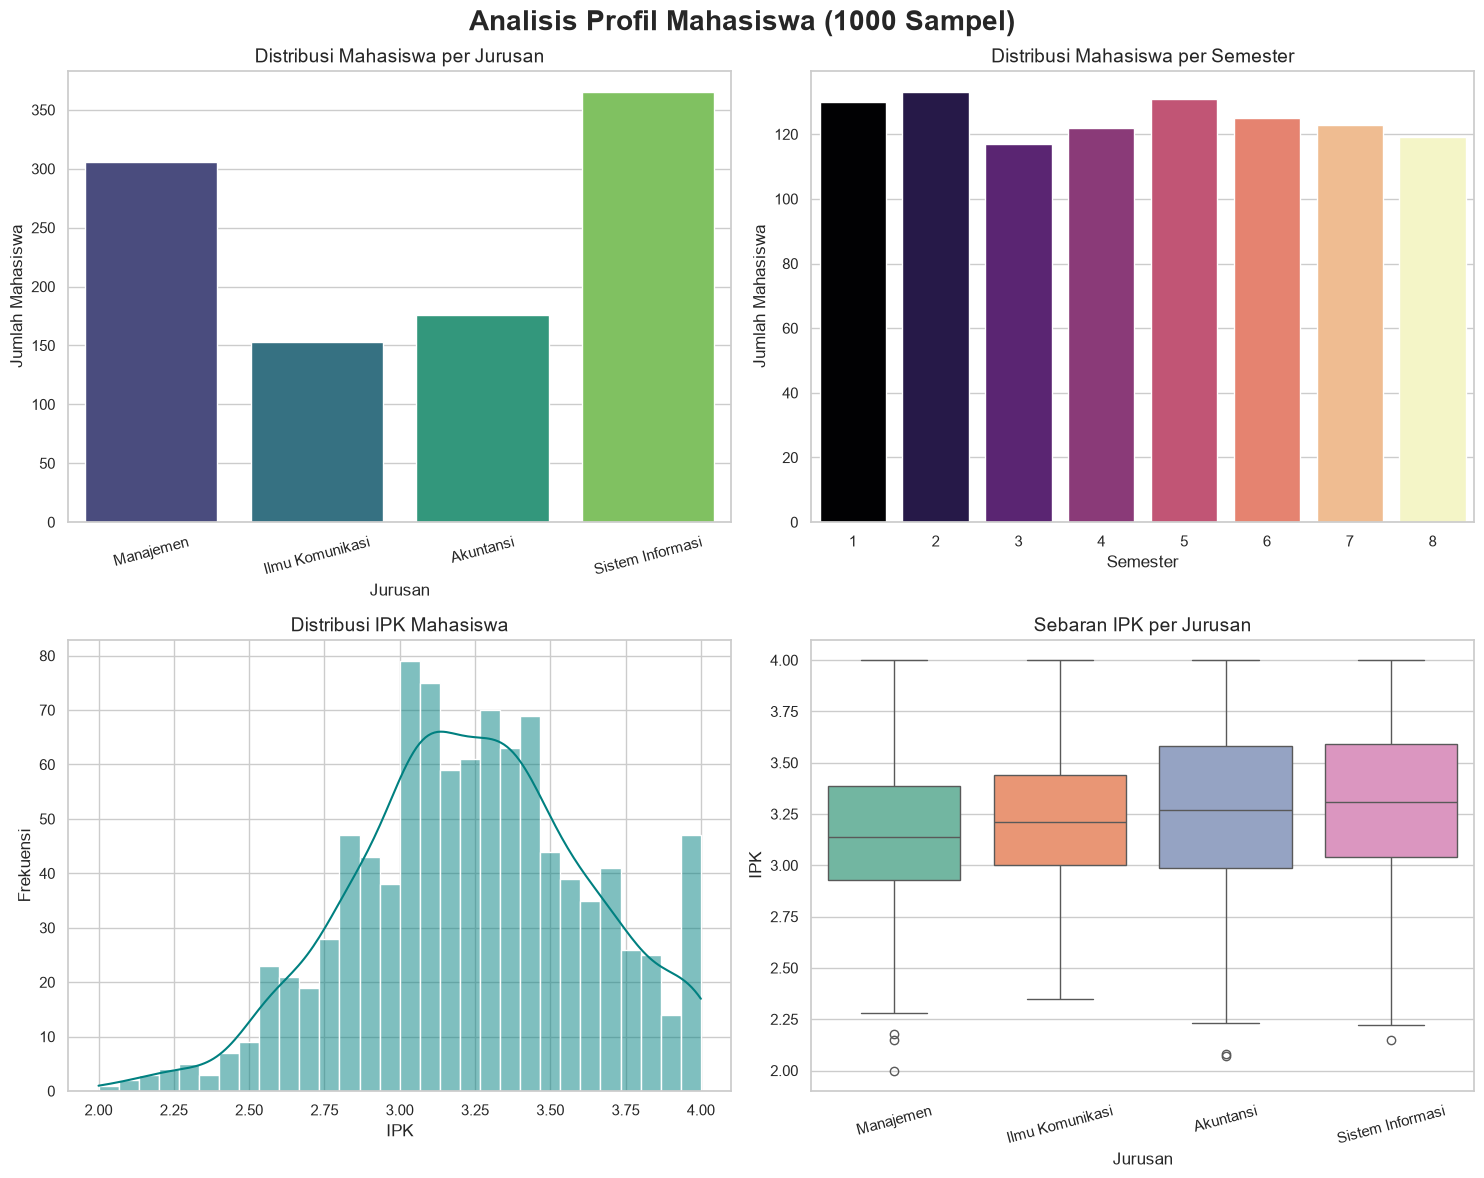

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Analisis Profil Mahasiswa (1000 Sampel)', fontsize=20, fontweight='bold')

# 1. Bar Chart: Jumlah Mahasiswa per Jurusan
# PERUBAHAN: Menambahkan hue='Jurusan' dan legend=False
sns.countplot(data=df, x='Jurusan', ax=axes[0, 0], hue='Jurusan', palette='viridis', legend=False)
axes[0, 0].set_title('Distribusi Mahasiswa per Jurusan', fontsize=14)
axes[0, 0].set_ylabel('Jumlah Mahasiswa')
axes[0, 0].tick_params(axis='x', rotation=15)

# 2. Bar Chart Berurutan: Jumlah Mahasiswa per Semester
# PERUBAHAN: Menambahkan hue='Semester' dan legend=False
sns.countplot(data=df, x='Semester', ax=axes[0, 1], hue='Semester', palette='magma', order=sorted(df['Semester'].unique()), legend=False)
axes[0, 1].set_title('Distribusi Mahasiswa per Semester', fontsize=14)
axes[0, 1].set_ylabel('Jumlah Mahasiswa')

# 3. Histogram: Distribusi IPK
sns.histplot(data=df, x='IPK', kde=True, ax=axes[1, 0], color='teal', bins=30)
axes[1, 0].set_title('Distribusi IPK Mahasiswa', fontsize=14)
axes[1, 0].set_ylabel('Frekuensi')

# 4. Box Plot: Sebaran IPK berdasarkan Jurusan
# PERUBAHAN: Menambahkan hue='Jurusan' dan legend=False
sns.boxplot(data=df, x='Jurusan', y='IPK', ax=axes[1, 1], hue='Jurusan', palette='Set2', legend=False)
axes[1, 1].set_title('Sebaran IPK per Jurusan', fontsize=14)
axes[1, 1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()